In [1]:
from langgraph.graph import StateGraph, START, END
from langchain_google_genai import ChatGoogleGenerativeAI
from langchain.messages import HumanMessage, SystemMessage
from typing import TypedDict, Annotated, Literal
from pydantic import BaseModel, Field
from dotenv import load_dotenv
import operator
import os


load_dotenv()
api_key = os.getenv("GEMINI_API_KEY")


In [2]:
generator_llm = ChatGoogleGenerativeAI(
    model="gemini-3.5-flash-lite",
    # temperature=0.8,
)

evaluator_llm = ChatGoogleGenerativeAI(
    model="gemini-3.5-flash-lite",
    # temperature=0,
)

optimizer_llm = ChatGoogleGenerativeAI(
    model="gemini-3.5-flash-lite",
    # temperature=0.6,
)

In [3]:
class TweetState(TypedDict):
    topic : str
    tweet : str
    evaluation : Literal["approved", "need_improvemnt"]
    feedback : str
    iteration : int
    max_iteration : int

In [4]:
class TweetEvaluation(BaseModel):
    evaluation : Annotated[Literal["approved", "need_improvemnt"], Field(..., description="Final Evaluation Result.")]
    feedback : str = Field(..., description="Feedback for the tweet.")


In [5]:
structure_evaluation_llm = evaluator_llm.with_structured_output(TweetEvaluation)

In [6]:
def generate_tweet(state: TweetState):
    topic = state['topic']

    message = [
        SystemMessage(content="You are a funny and clever tweeter/x influuencer."),
        HumanMessage(content=f"""

    Write a short, original, and hilarious tweet on the topic: '{topic}'.
    Rules :
     - Do Not use question answer format.
     - Max 180 Character.
     - Use observational humor, irony, sarcasm, or cultural reference.
     - Think in meme logic, punchlines or relatable takes.
     - Use simple day to day english.

""")
    ]

    response = generator_llm.invoke(message)

    return {'tweet' : response.text}

In [7]:
def evaluate_tweet(state: TweetState):
    message = [
        SystemMessage(content="You are a ruthless, no-laugh-given Twitter critic. You evaluate tweets based on humor, originality, virality, and tweet format.") ,
        HumanMessage(content=f"""
Evaluate the following tweet:

Tweet: "{state['tweet']}"

Use the criteria below to evaluate the tweet:

1. Originality - Is this fresh, or have you seen it a hundred times before?
2. Humor - Did it genuinely make you smile, laugh, or chuckle?
3. Punchiness - Is it short, sharp, and scroll-stopping?
4. Virality Potential - Would people retweet or share it?
5. Format - Is it a well-formed tweet (not a setup-punchline joke, not a Q&A joke, and under 280 characters)?

Auto-reject if:
- It's written in question-answer format (e.g., "Why did..." or "What happens when...")
- It exceeds 280 characters
- It reads like a traditional setup-punchline joke
- Don't end with generic, throwaway, or deflating lines that weaken the humor (e.g., "Masterpieces...")

### Respond ONLY in structured format:
- evaluation: "approved" or "needs_improvement"
- feedback: One paragraph explaining the strengths and weaknesses
""")
    ]

    response = structure_evaluation_llm.invoke(message)

    return {'evaluation' : response.evaluation, 'feedback' : response.feedback}

In [8]:
def optimize_tweet(state : TweetState):
    message = [
        SystemMessage(content="You patch up tweets for virality and humor based on given feedback."),
        HumanMessage(content=f"""Improve the tweet based on this feedback : 
        "{state['feedback']}"

        Topic : {state['topic']}

        Re-write it as a short, viral worthy tweet. Avoid Q&A style and stay under 280 character.
        """)
    ]

    response = optimizer_llm.invoke(message).text
    iteration = state['iteration'] + 1
    return {'tweet' : response, "iteration" : iteration}

In [9]:
def route_evaluation(state: TweetState):
    if state['feedback'] == "improvemnt" or state['iteration'] >= state['max_iteration']:
        return "approved"
    else:
        return "need_approved"


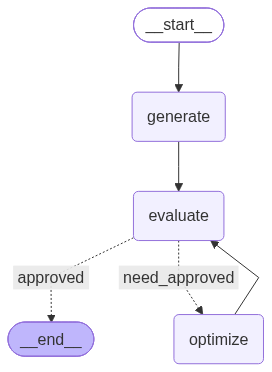

In [10]:
graph = StateGraph(TweetState)

graph.add_node('generate', generate_tweet)
graph.add_node('evaluate', evaluate_tweet)
graph.add_node('optimize', optimize_tweet)

graph.add_edge(START, 'generate')
graph.add_edge('generate', 'evaluate')
graph.add_conditional_edges('evaluate', route_evaluation, {"approved" : END, "need_approved" : 'optimize'})
graph.add_edge('optimize', 'evaluate')


workflow = graph.compile()
workflow

In [11]:
initial_state = {
    "topic" : "Java programming",
    "iteration" : 1,
    "max_iteration" : 5
}

final_stage = workflow.invoke(initial_state)
final_stage


Direct use of automatic function calling (AFC) in Models.generate_content is not recommended. Instead, we recommend to use AFC in Chat.send_message. Similarly, direct use of AFC in Models.generate_content_stream is not recommended. Instead, we recommend to use AFC in Chat.send_message_stream.


{'topic': 'Java programming',
 'tweet': 'Nobody:\nNot a single soul:\n\nEnterprise Java developers writing a simple "Hello World":\n\n• Imports 47 abstract factory builders\n• Configures 3 XML files from 2008\n• Wraps a String in a SingletonProxyFactoryBean\n• Throws a NullPointerException from 2014\n\nJust print the damn text.',
 'evaluation': 'approved',
 'feedback': "This tweet takes a classic, well-worn developer trope and executes it with surgical precision. The use of the dead 'Nobody:' format is slightly dated, but the specific technical exaggerations—XML files from 2008 and ancient NullPointerExceptions—are painfully accurate and genuinely funny to anyone who has touched Enterprise Java. It is well under the character limit, visually well-formatted with bullet points, and has massive retweet potential among software engineers. Despite relying on a slightly tired meme format, the specific punchiness of the punchline carries it over the finish line.",
 'iteration': 5,
 'max_itera